<a href="https://colab.research.google.com/github/JorgeLuisMadrid/Aprendizaje-Maquina-2026B/blob/main/L05_Red_Neuronal_Densa_TF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Red Neuronal Densa en TensorFlow
## Dr. Carlos Villaseñor

Paso 1. Correr paqueterias

In [18]:
# Paquetería básica
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Importamos Tensorflow y Keras
import tensorflow as tf
from tensorflow import keras

# Usamos funcionalidades básicas de Sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

Paso 2. Carga el archivo 'auto-mpg.csv' y haz la lectura con pandas

In [ ]:
!wget 'https://github.com/Dr-Carlos-Villasenor/Clase_Aprendizaje_Profundo/raw/main/Datasets/auto-mpg.csv'

In [ ]:
dataset = pd.read_csv('auto-mpg.csv')
dataset.head()

Paso 3. Limpieza de los datos

In [ ]:
dataset.info()

In [ ]:
np.array(dataset.horsepower)

In [ ]:
dataset['horsepower'].replace('?', np.nan, inplace=True)
np.array(dataset.horsepower)

In [ ]:
dataset = dataset.dropna()

Paso 3. Revisar datos faltantes

In [ ]:
dataset.isna().sum()

Paso 6. Condificación one-hot a columnas del país

In [ ]:
origin = dataset.pop('origin')
dataset['USA'] = (origin == 1)*1.0
dataset['Europe'] = (origin == 2)*1.0
dataset['Japan'] = (origin == 3)*1.0
dataset.tail()

Paso 7. Elige las variables de entrada y salida

In [ ]:
x = np.asanyarray(dataset.drop(columns=['mpg', 'car name']))
y = np.asanyarray(dataset[['mpg']])
x = StandardScaler().fit_transform(x)
print(x.shape)
print(y.shape)

Paso 8. Particiona el dataset

In [ ]:
xtrain, xtest, ytrain, ytest = train_test_split(x, y, test_size=0.2)

Paso 9. Crea una red neuronal para aprender los datos. En este caso creamos la metrica de regresión R2,

In [ ]:
from keras import backend as K

def r2score(y_true, y_pred):
    SS_res = K.sum(K.square(y_true - y_pred))
    SS_tot = K.sum(K.square(y_true - K.mean(y_true)))
    return 1 - SS_res / (SS_tot + K.epsilon())

In [ ]:
def build_model():

  model = keras.Sequential()
  model.add(keras.layers.Dense(128, activation='relu', input_shape=[x.shape[1]]))
  model.add(keras.layers.Dropout(0.2))
  model.add(keras.layers.Dense(32, activation='tanh'))
  model.add(keras.layers.Dense(1, activation='linear'))

  model.compile(loss='mean_squared_error',
                optimizer=keras.optimizers.Adam(),
                metrics=[keras.metrics.MAE, r2score])
  return  model

In [ ]:
model = build_model()
model.summary()

Paso 10. Entrena la red neuronal

In [16]:
history = model.fit(xtrain, ytrain,
                    batch_size=150, epochs=3000,
                    validation_data=(xtest, ytest), verbose=1)

Streaming output truncated to the last 5000 lines.
Epoch 501/3000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - loss: 12.5596 - mean_absolute_error: 2.3082 - r2score: 0.7833 - val_loss: 15.2530 - val_mean_absolute_error: 2.6948 - val_r2score: 0.7527
Epoch 502/3000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - loss: 12.4405 - mean_absolute_error: 2.3000 - r2score: 0.7884 - val_loss: 15.2655 - val_mean_absolute_error: 2.7001 - val_r2score: 0.7525
Epoch 503/3000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - loss: 12.4183 - mean_absolute_error: 2.2654 - r2score: 0.8206 - val_loss: 15.2621 - val_mean_absolute_error: 2.6949 - val_r2score: 0.7526
Epoch 504/3000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 12.0495 - mean_absolute_error: 2.2458 - r2score: 0.7515 - val_loss: 15.2210 - val_mean_absolute_error: 2.6894 - val_r2score: 0.7533
Epoch 505/3000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 12.3332 - mean_absolute_error: 2.3068 - r2score: 0.7620 - val_loss: 15.1268 - val_mean_absolute_error: 2.6807 - val_

Paso 11. Dibuja las curvas de aprendizaje para un mejor diagnóstico del aprendizaje

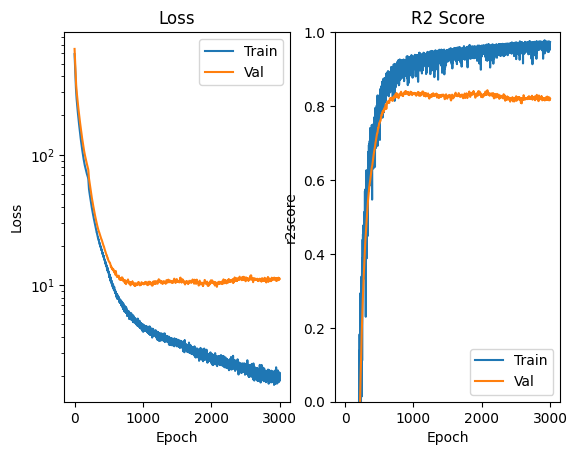

In [17]:
def plot_history(history):
  hist = pd.DataFrame(history.history)
  hist['epoch'] = history.epoch
  plt.figure()
  plt.subplot(121)
  plt.title('Loss')
  plt.xlabel('Epoch')
  plt.ylabel('Loss')
  plt.plot(hist['epoch'], hist['loss'],
           label='Train')
  plt.plot(hist['epoch'], hist['val_loss'],
           label = 'Val')
  plt.yscale('log')
  plt.legend()

  plt.subplot(122)
  plt.title('R2 Score')
  plt.xlabel('Epoch')
  plt.ylabel('r2score')
  plt.plot(hist['epoch'], hist['r2score'],
           label='Train')
  plt.plot(hist['epoch'], hist['val_r2score'],
           label = 'Val')
  plt.ylim([0,1])
  plt.legend()

plot_history(history)

Paso 12. Implementación de Eary Stopping como regulador

Epoch 1/3000
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 133ms/step - loss: 591.8975 - mean_absolute_error: 23.0829 - r2score: -11.1248 - val_loss: 640.9322 - val_mean_absolute_error: 24.0975 - val_r2score: -9.3899
Epoch 2/3000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 569.2935 - mean_absolute_error: 22.6153 - r2score: -9.0284 - val_loss: 617.9236 - val_mean_absolute_error: 23.6279 - val_r2score: -9.0169
Epoch 3/3000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 550.1288 - mean_absolute_error: 22.1938 - r2score: -9.7695 - val_loss: 595.8629 - val_mean_absolute_error: 23.1668 - val_r2score: -8.6593
Epoch 4/3000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 529.7115 - mean_absolute_error: 21.7485 - r2score: -10.4142 - val_loss: 574.8873 - val_mean_absolute_error: 22.7155 - val_r2score: -8.3193
Epoch 5/3000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 511.9181 - mean_absolute_error: 21.3382 - r2score: -7.1709 - val_loss: 554.7571 - val_mean_absolute_error: 22.2721 - val_r2score: -7.9929
Epoch 6/3000

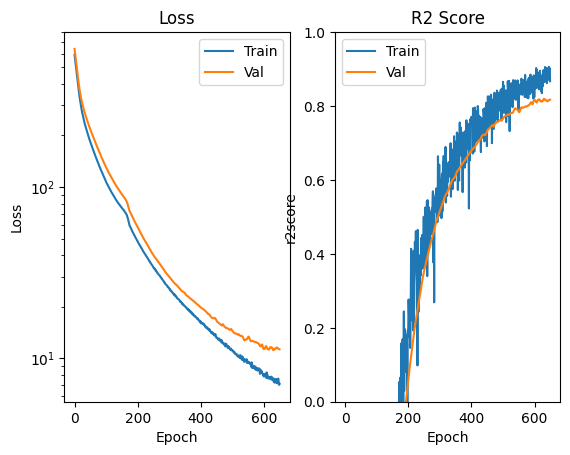

In [19]:
es = keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=20)
model = build_model()
history = model.fit(xtrain, ytrain,
                    batch_size=150, epochs=3000,
                    validation_data=(xtest, ytest),
                    verbose=1, callbacks=[es])
plot_history(history)